# Retail Demand Forecasting — Exploratory Data Analysis

**Project:** Retail Demand Forecasting and Replenishment System
**Dataset:** `data/raw/retail_sales.csv` — **synthetic data generated by Python**, not real business data. It has the same columns a real retail export would have, so the same notebook works if you drop in real numbers.

**What this notebook does**
1. Loads the dataset and shows its structure.
2. Checks missing values and data quality.
3. Explores sales patterns with charts: daily, monthly, category, store, promotion and stock.
4. Records the findings that drive the modelling decisions in `main.py`.

This notebook **reuses the project code** in `src/`, so the charts here are exactly the ones saved in `outputs/charts/`.

In [1]:
# Make the project root importable (the notebook lives in notebooks/, code lives in src/)
import os, sys
from pathlib import Path

PROJECT_ROOT = Path(os.path.abspath(".."))
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config
from src import data_preprocessing, eda

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
print("Project root:", PROJECT_ROOT)

Project root: /home/user/retail-demand-forecasting


## 1. Load the data

If `data/processed/retail_sales_cleaned.csv` does not exist yet, the notebook creates it
(which also generates the synthetic raw dataset when needed). That way the notebook is
self-contained and can be run before `main.py`.

In [2]:
if config.CLEANED_DATA_FILE.exists():
    df = pd.read_csv(config.CLEANED_DATA_FILE, parse_dates=[config.DATE_COL])
    print("Loaded cleaned data from", config.CLEANED_DATA_FILE)
else:
    print("Cleaned data not found -> running preprocessing (creates synthetic data if needed)...")
    df = data_preprocessing.run_preprocessing()

df.head()

Loaded cleaned data from /home/user/retail-demand-forecasting/data/processed/retail_sales_cleaned.csv


,date,store_id,product_id,product_category,sales_quantity,unit_price,promotion,stock_available
0,2023-01-01,S01,P001,Beverages,81,45.16,1,203
1,2023-01-01,S01,P002,Dairy,98,54.91,1,260
2,2023-01-01,S01,P003,Household,26,146.27,0,133
3,2023-01-01,S01,P004,Snacks,48,34.29,0,255
4,2023-01-01,S01,P005,Beverages,53,51.21,0,85


## 2. Dataset overview — shape, columns and data types

In [3]:
print("Shape:", df.shape)
print()
info_table = eda.dataset_overview(df)
info_table

Shape: (35083, 8)


--- DATASET OVERVIEW ---
Rows: 35,083   Columns: 8
Date range: 2023-01-01 -> 2024-12-31
Stores: 4   Products: 12   Categories: 4

Column information:
                           dtype  missing_values  missing_percent  unique_values
date              datetime64[ns]               0              0.0            731
store_id                  object               0              0.0              4
product_id                object               0              0.0             12
product_category          object               0              0.0              4
sales_quantity             int64               0              0.0            261
unit_price               float64               0              0.0           4135
promotion                  int64               0              0.0              2
stock_available            int64               0              0.0            973

Numeric summary:
       sales_quantity  unit_price  stock_available  promotion
count        35083.00

,dtype,missing_values,missing_percent,unique_values
date,datetime64[ns],0,0.0,731
store_id,object,0,0.0,4
product_id,object,0,0.0,12
product_category,object,0,0.0,4
sales_quantity,int64,0,0.0,261
unit_price,float64,0,0.0,4135
promotion,int64,0,0.0,2
stock_available,int64,0,0.0,973


In [4]:
# Raw file, before cleaning: useful to show how dirty the source data was
raw = pd.read_csv(config.RAW_DATA_FILE)
print("Raw rows:", len(raw), "| Cleaned rows:", len(df))
print("\nMissing values in the RAW file:")
print(raw.isna().sum().to_string())
print("\nExact duplicate rows in the RAW file:", raw.duplicated().sum())

Raw rows: 35228 | Cleaned rows: 35083

Missing values in the RAW file:
date                  0
store_id              0
product_id            0
product_category      0
sales_quantity      351
unit_price          280
promotion           175
stock_available     353

Exact duplicate rows in the RAW file: 140


## 3. Missing value analysis

The raw export contains missing quantities, prices, stock and promotion flags, plus
duplicate rows, impossible dates (`31/02/2024`) and negative sales. `src/data_preprocessing.py`
fixes all of that:

| Problem | Treatment |
|---|---|
| impossible / unparseable date | row dropped (no reliable date = unusable for a time series) |
| exact duplicate rows | dropped |
| missing `sales_quantity` | median of the same store+product |
| missing `unit_price` | median price of the same product |
| missing `stock_available` | median of the same store+product, else 0 |
| missing `promotion` | assumed 0 (no promotion) |
| negative sales / stock / zero price | treated as missing, then imputed |
| extreme outliers | capped at 10× the store-product median |

After cleaning there are **no missing values** left:

In [5]:
print("Missing values in the CLEANED data:", df.isna().sum().sum())
df.isna().sum().to_string()

Missing values in the CLEANED data: 0


'date                0\nstore_id            0\nproduct_id          0\nproduct_category    0\nsales_quantity      0\nunit_price          0\npromotion           0\nstock_available     0'

## 4. Sales distribution

  chart saved -> 00_sales_distribution.png


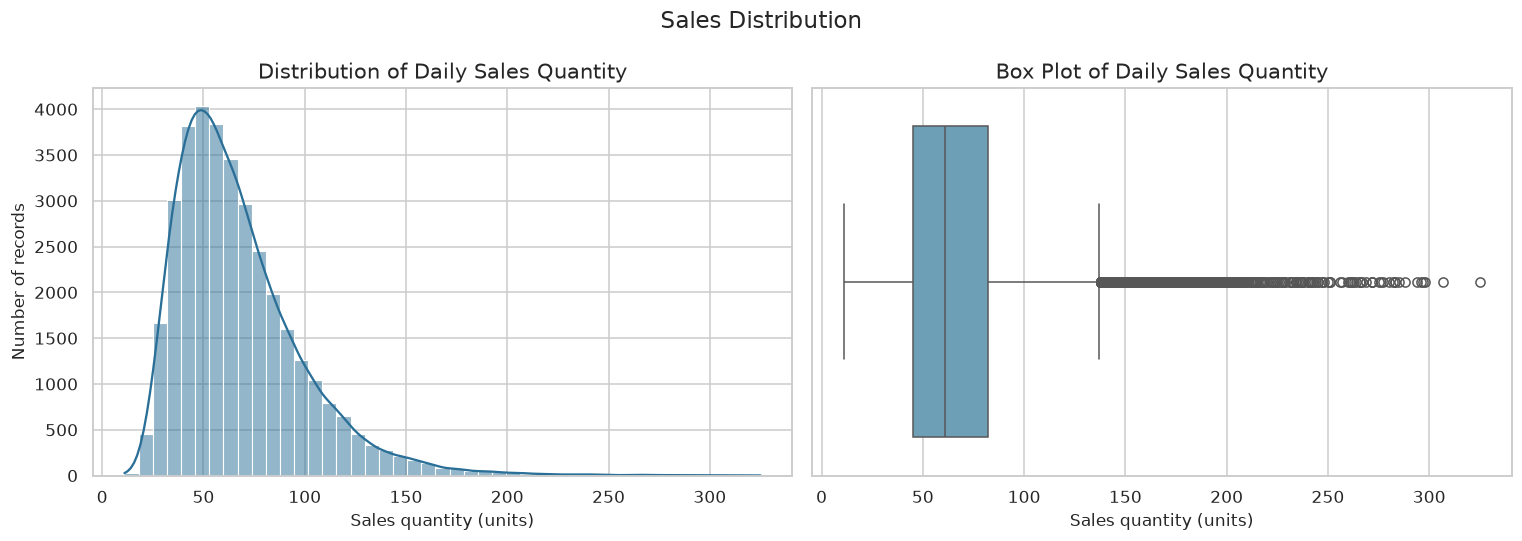

In [6]:
eda.plot_sales_distribution(df)
display(Image(filename=str(config.CHARTS_DIR / "00_sales_distribution.png")))

In [7]:
df[config.TARGET_COL].describe().round(2).to_string()

'count    35083.00\nmean        67.47\nstd         31.51\nmin         11.00\n25%         45.00\n50%         61.00\n75%         82.00\nmax        325.00'

**Reading it:** daily sales are right-skewed. Most days sell 30–90 units, weekends and
promotion days push into the tail. This matters for evaluation: a plain average error
(MAE) is easier to explain, while RMSE will be dominated by those big weekend days.

## 5. Daily and monthly sales trends

  chart saved -> 01_daily_sales_trend.png


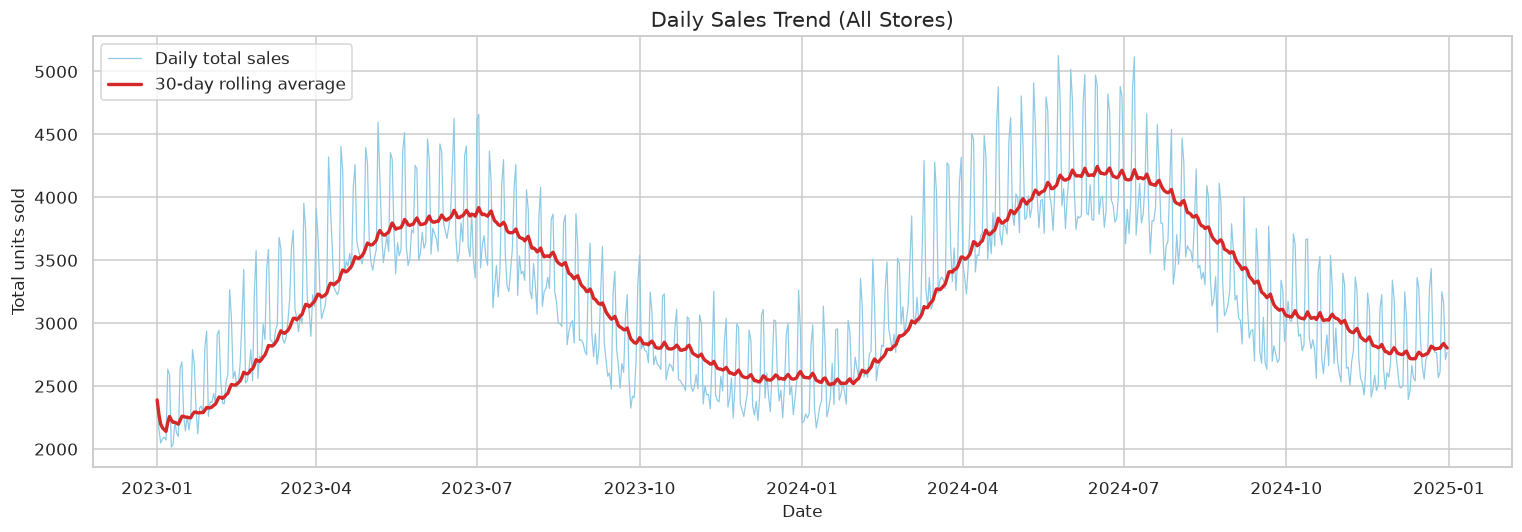

In [8]:
eda.plot_daily_trend(df)
display(Image(filename=str(config.CHART_DAILY_TREND)))

  chart saved -> 02_monthly_sales_trend.png


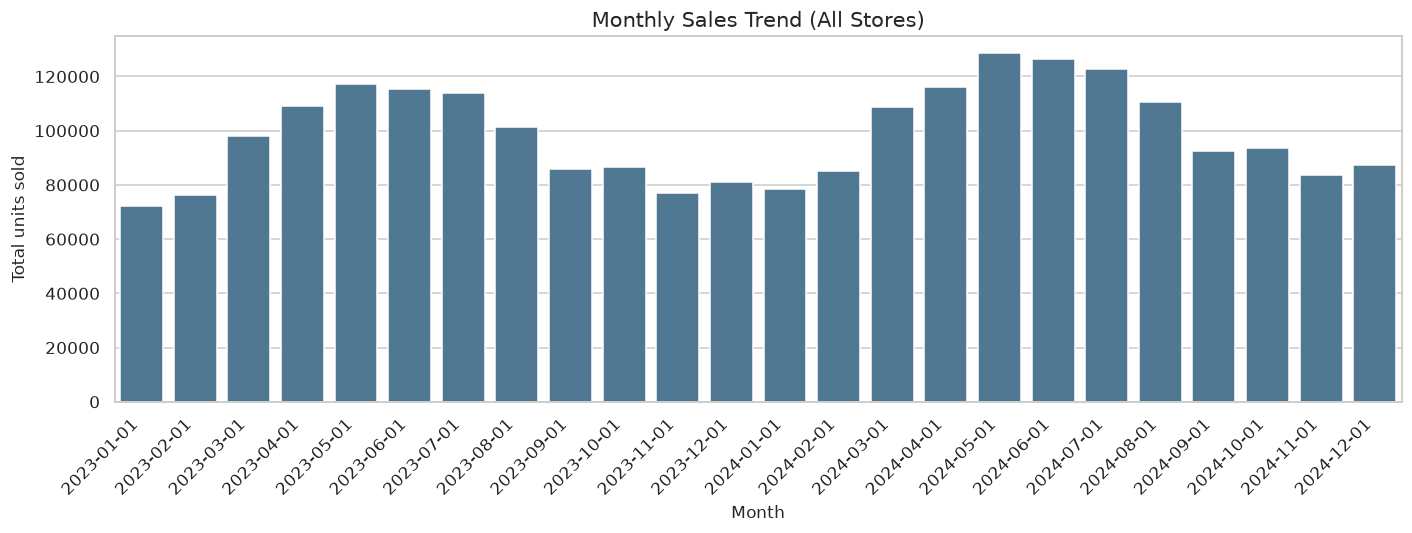

In [9]:
eda.plot_monthly_trend(df)
display(Image(filename=str(config.CHART_MONTHLY_TREND)))

In [10]:
# Quantify the two seasonalities the models must learn
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = df.groupby(df[config.DATE_COL].dt.dayofweek)[config.TARGET_COL].mean()
by_weekday.index = [weekday_names[i] for i in by_weekday.index]

by_month = df.groupby(df[config.DATE_COL].dt.month)[config.TARGET_COL].mean()

print("Average sales by weekday:")
print(by_weekday.round(1).to_string())
print("\nAverage sales by month:")
print(by_month.round(1).to_string())
print("\nWeekend vs weekday average:")
print(df.groupby('is_weekend')[config.TARGET_COL].mean().round(2).to_string()
      if 'is_weekend' in df else "is_weekend not in this table (it is created in feature engineering)")

Average sales by weekday:
Mon    63.5
Tue    62.7
Wed    63.4
Thu    63.4
Fri    63.4
Sat    78.2
Sun    77.8

Average sales by month:
date
1     50.6
2     59.1
3     69.5
4     78.2
5     82.6
6     84.0
7     79.5
8     71.2
9     61.8
10    60.5
11    55.7
12    56.5

Weekend vs weekday average:
is_weekend not in this table (it is created in feature engineering)


**Reading it:** there is a clear weekly rhythm (Saturday/Sunday are the strongest days) and a
yearly rhythm (a festive peak around October–December). This is exactly why the project uses
`day_of_week`, `is_weekend` and `month` as features, and why a **chronological** train/test
split is essential — a random split would hide how hard the festive period really is.

## 6. Product category-wise sales

  chart saved -> 03_category_wise_sales.png


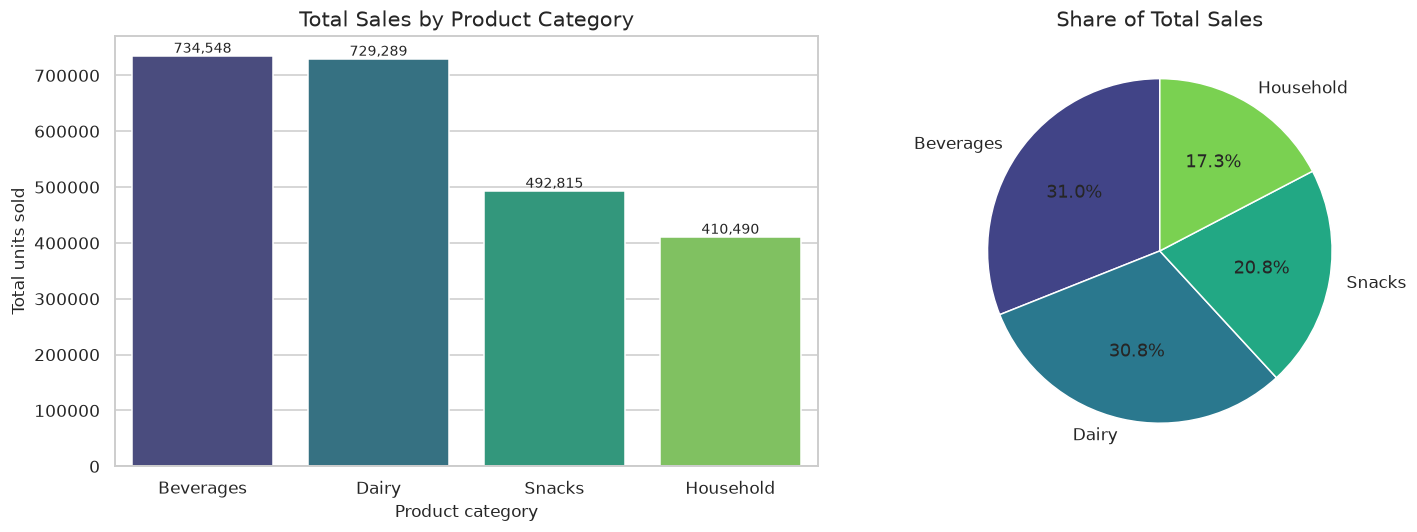

,total_units,average_units,average_price,records
product_category,,,,
Beverages,734548,83.76,47.57,8770
Dairy,729289,83.16,58.69,8770
Snacks,492815,56.18,38.50,8772
Household,410490,46.80,152.03,8771


In [11]:
eda.plot_category_sales(df)
display(Image(filename=str(config.CHART_CATEGORY_SALES)))

category_summary = df.groupby("product_category").agg(
    total_units=(config.TARGET_COL, "sum"),
    average_units=(config.TARGET_COL, "mean"),
    average_price=("unit_price", "mean"),
    records=(config.TARGET_COL, "size"),
).round(2).sort_values("total_units", ascending=False)
category_summary

**Reading it:** Dairy and Beverages are the volume drivers, which is why they also produce the
largest absolute errors (see `outputs/category_errors.csv`). Absolute errors scale with the size
of the category — a 15-unit miss on a 120-unit product is a 12% error, while the same 15-unit
miss on a 30-unit Household product would be a 50% error. That is why the evaluation report
shows **both** MAE and MAPE per category.

## 7. Store-wise sales comparison

  chart saved -> 04_store_wise_sales.png


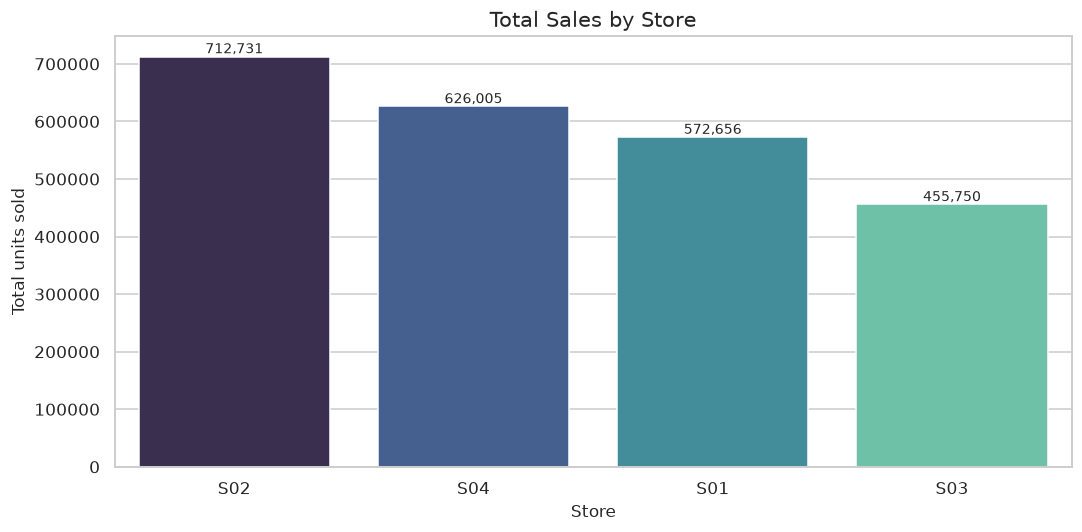

,total_units,average_units,average_stock
store_id,,,
S02,712731,81.25,304.61
S04,626005,71.39,266.62
S01,572656,65.29,245.55
S03,455750,51.96,194.53


In [12]:
eda.plot_store_sales(df)
display(Image(filename=str(config.CHART_STORE_SALES)))

store_summary = df.groupby("store_id").agg(
    total_units=(config.TARGET_COL, "sum"),
    average_units=(config.TARGET_COL, "mean"),
    average_stock=("stock_available", "mean"),
).round(2).sort_values("total_units", ascending=False)
store_summary

**Reading it:** stores differ in size, so the model needs store-level history. This is why
lag and rolling features are computed **per store and per product** instead of globally —
a busy store's numbers must never become another store's lag feature.

## 8. Promotion versus non-promotion sales

  chart saved -> 05_promotion_vs_non_promotion.png


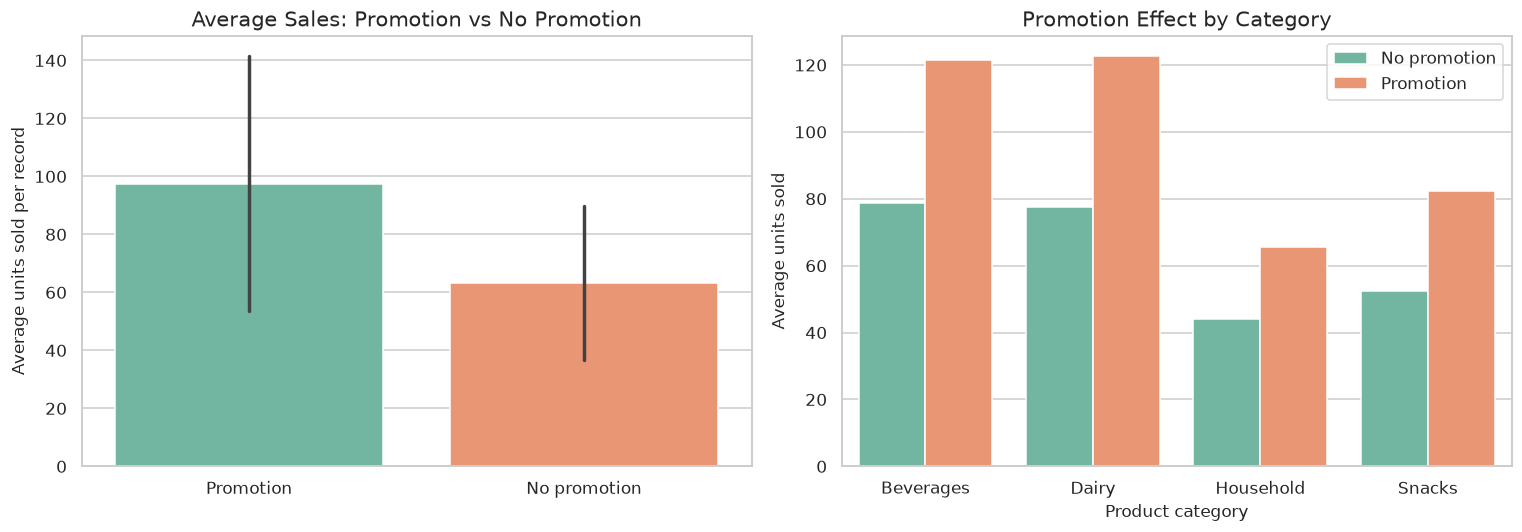

,mean,count
No promotion,63.14,30659
Promotion,97.50,4424


In [13]:
eda.plot_promotion_effect(df)
display(Image(filename=str(config.CHART_PROMOTION)))

promo_summary = df.groupby("promotion")[config.TARGET_COL].agg(["mean", "count"]).round(2)
promo_summary.index = ["No promotion", "Promotion"]
promo_summary

In [14]:
# How much of a lift does a promotion give, overall and per category?
overall_lift = promo_summary.loc["Promotion", "mean"] / promo_summary.loc["No promotion", "mean"]
print(f"Overall promotion lift: {overall_lift:.2f}x")

lift_by_category = (
    df.groupby(["product_category", "promotion"])[config.TARGET_COL].mean()
    .unstack()
    .rename(columns={0: "no_promo", 1: "promo"})
)
lift_by_category["lift_x"] = (lift_by_category["promo"] / lift_by_category["no_promo"]).round(2)
lift_by_category.round(2)

Overall promotion lift: 1.54x


promotion,no_promo,promo,lift_x
product_category,,,
Beverages,78.61,121.55,1.55
Dairy,77.42,122.66,1.58
Household,43.98,65.65,1.49
Snacks,52.34,82.41,1.57


**Reading it:** promotion days sell clearly more, and the effect differs by category. Promotion
is therefore a valid **known-in-advance** feature: for the future we assume no promotion, because
the promo calendar is not part of this dataset (a documented limitation of the forecast).

## 9. Stock availability analysis

  chart saved -> 05b_stock_analysis.png


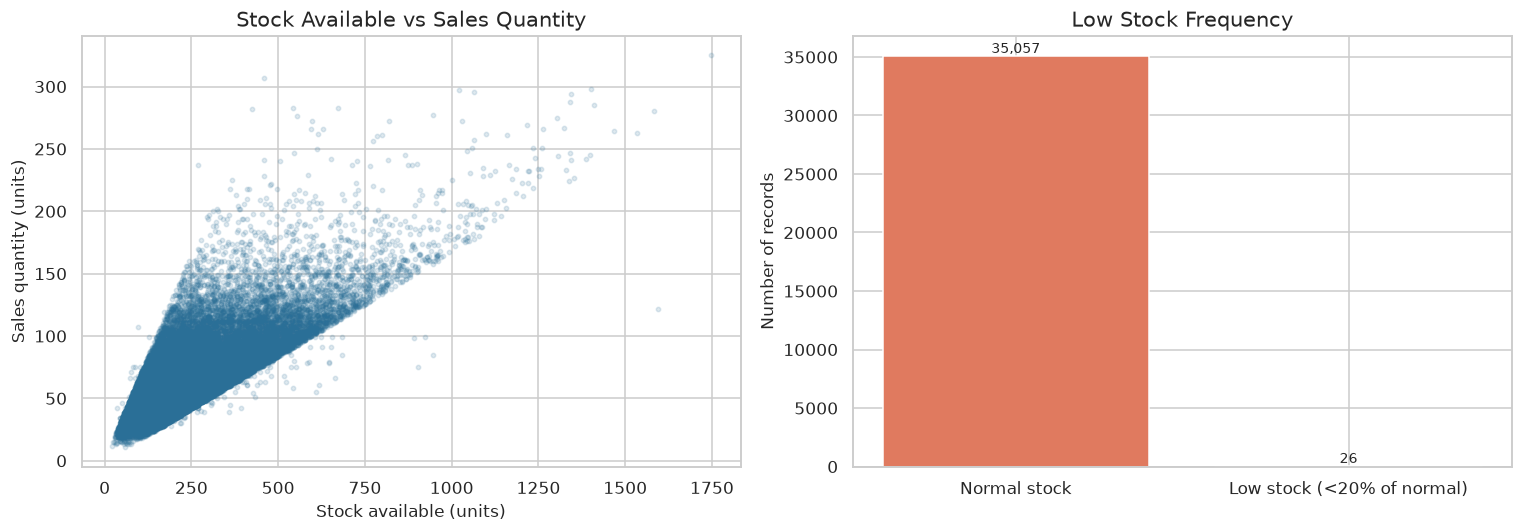

In [15]:
eda.plot_stock_analysis(df)
display(Image(filename=str(config.CHARTS_DIR / "05b_stock_analysis.png")))

In [16]:
# How often does stock drop below what the product normally sells in a day?
df_stock = df.copy()
daily_avg = df_stock.groupby(config.GROUP_COLS)[config.TARGET_COL].transform("mean")
stockout_risk = (df_stock["stock_available"] < daily_avg).mean() * 100
print(f"Records where stock < average daily demand: {stockout_risk:.1f}%")
print(f"Average stock cover (stock / average daily demand): "
      f"{(df_stock['stock_available'] / daily_avg).mean():.2f} days")

Records where stock < average daily demand: 0.7%
Average stock cover (stock / average daily demand): 3.75 days


**Reading it:** stock clearly caps sales on some days, and stock cover varies a lot between
products. That is the business problem the replenishment step solves: it converts the forecast
into a concrete order quantity using expected lead-time demand plus a safety buffer.

## 10. Findings that drive the modelling decisions

1. **Two strong seasonalities** — weekly (weekend peaks) and yearly (festive peak) → calendar
   features `day_of_week`, `is_weekend`, `month`.
2. **Sales are highly autocorrelated** — yesterday's and last week's sales predict today's well
   → `lag_1`, `lag_7`, `lag_30`, `rolling_mean_7`, `rolling_mean_30` (all shifted by one day so
   the current day's sales never leak into its own features).
3. **Stores and products differ in scale** → lag/rolling features are grouped by store + product.
4. **Promotions lift sales** and are known in advance → used as a feature; future forecasts assume
   no promotion.
5. **Data quality is imperfect** → cleaning handles missing values, duplicates, impossible dates
   and negative sales before any modelling happens.
6. **Errors must be read per category** → MAE is large for high-volume categories (Dairy,
   Beverages) but MAPE is more even; both are reported.

**Next step:** run `python main.py` to train the models, forecast the next 7 days and produce
reorder recommendations, then `streamlit run app.py` for the dashboard.